In [51]:
from audioop import rms
# from tkinter import E
import numpy as np
from matplotlib import pyplot as plt
import scipy.io as sio
from monolithic.math.statistics import rmse, vrr,pv
from scipy import *
from scipy import signal
from monolithic.plot import show_surface_map
from monolithic.math import remove_surface, remove_sphere, remove_polynomials
import copy
from mpl_toolkits.mplot3d import Axes3D

In [52]:
g = 0.1   #阻尼因子,值≤1时，g值越大收敛速度越快，而g值过大则迭代发散
s = 0.95  #s是g的修正系数,s的值最好是接近1的值

In [53]:
surfFile = 'E:\\Multi-Tool-main\\Multi-Tool-main\\1-initial-map\\data\\initial_map_rectangular_pap_60mm.mat'
readData = sio.loadmat(surfFile) # 读出readData的内容
X = readData['X']
Y = readData['Y']
Z = readData['Z']

dx = np.median(np.diff(X[0, :]))

print("Lateral resolution = ", dx, " m")

Lateral resolution =  0.00022222167172003537  m


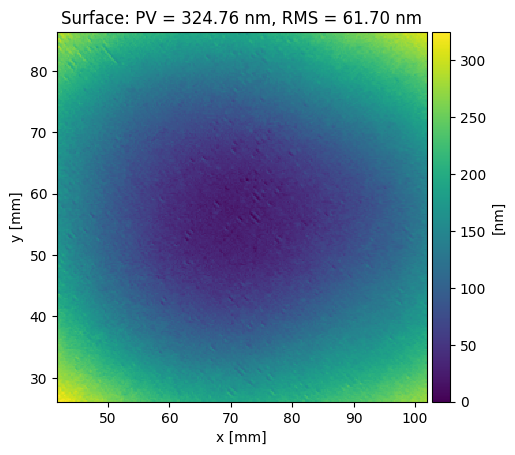

In [54]:
show_surface_map(X, Y, Z)
plt.show()

In [55]:
def tif_surpergaussian_2d(
    x2d: np.ndarray,
    y2d: np.ndarray,
    t: float,
    a: float,
    sigma1d: np.ndarray,
    mu1d: np.ndarray = np.array([0, 0]),
    p: float = 1.0
) -> np.ndarray:
    '''
    Returns a 2D super Gaussian function
    Parameters
    ----------
        x2d: `numpy.ndarray`
            x coordinates [m] 
        y2d: `numpy.ndarray`
            y coordinates [m]
        t: `float`
            dwell time [m]
        a: `float`
            PRR [m/s]
        sigma1d: `numpy.ndarray`
            variances in x and y [m]
        mu1d: `numpy.ndarray`
            mu[2] = center x and y
        p: `numpy.ndarray`
            power
    
    Returns
    -------
        `numpy.ndarray`
        2D Super Gaussian profile
    '''
    return t * a * np.exp(-((x2d - mu1d[0])**2 / (2 * sigma1d[0]**2) + (y2d - mu1d[1])**2 / (2 * sigma1d[1]**2))**p)

In [56]:
Xtif, Ytif = np.meshgrid(np.linspace(-5e-3, 5e-3, int(10e-2 / dx) + 1),
                    np.linspace(-5e-3, 5e-3, int(10e-2 / dx + 1)))

Ytif = -Ytif
R = tif_surpergaussian_2d(
    Xtif, Ytif,
    1,
    7e-9,
    [2.77e-2, 2.77e-2],
    [0, 0],
    2
)

R = R[90:-90,90:-90]



In [57]:
R.shape

(271, 271)

In [58]:
H0 =  Z
dx = 20  # x,y:tif的区域  
dy = 20
VR = 1 #vrr(R,dx,dy) # 去除函数的体积去除率,确定初始停留时间和停留时间的修正量

def rms(x: np.ndarray) -> float:
    """Calculate the RMS of all the element in the input data.

    Args:
        x (numpy.ndarray): the input `numpy` array of data.

    Returns:
        float: the RMS error of all the element in x.
    """
    return np.sqrt(np.nanmean(np.square(x.ravel())))

In [59]:
def itea(E,H0,R,VR,D,g):
    deltak = E / VR
    D = D + g*deltak
    D[D<0]=0
    E = H0 - signal.convolve2d(R, D, 'same')
    return E,D

In [60]:
def ite(H0,R,VR,g,s):
    """迭代计算驻留时间"""
    H0 = H0 - np.nanmin(H0) #将H0处理为非负,它还能保证获得的驻留时间是非负的
    D0 = H0 / VR   #初始驻留时间
    E0 = H0 - signal.convolve2d(R, D0, 'same') #初始表面残差
    D = D0
    E = E0
    a = np.fix(len(E)/4).astype(int)
    k = 0
    while 1:
        b = E[a:-a,a:-a]
        c = itea(E,H0,R,VR,D,g)[0][a:-a,a:-a]
        if rms(c)/rms(b) >= 0.999:
            _,D = itea(E,H0,R,VR,D,g)
            break
        if rms(b) < rms(c) :
            if rms(b)/rms(H0) < 0.1:
                E,D = itea(E,H0,R,VR,D,g)
                break
            else:
                g = s*g
                E,D = itea(E,H0,R,VR,D,g) 
        else:
            E,D = itea(E,H0,R,VR,D,g)
            k =k +1  
            
    return E,D  


In [61]:
E,D = ite(H0,R,VR,g,s)

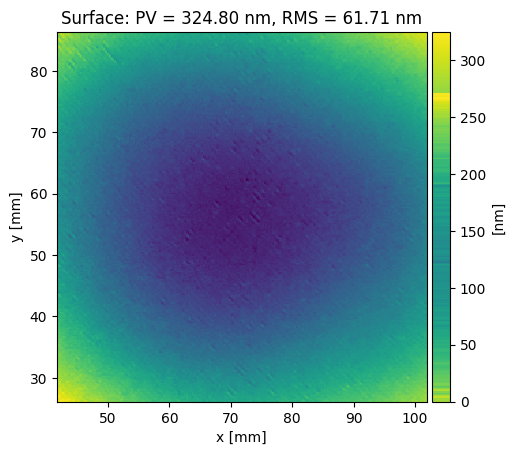

In [62]:
show_surface_map(X,Y,E)
plt.pcolormesh(D)
plt.show()

C:\Users\22267\AppData\Local\Temp\ipykernel_8100\1690167450.py:2: MatplotlibDeprecationWarning: Axes3D(fig) adding itself to the figure is deprecated since 3.4. Pass the keyword argument auto_add_to_figure=False and use fig.add_axes(ax) to suppress this warning. The default value of auto_add_to_figure will change to False in mpl3.5 and True values will no longer work in 3.6.  This is consistent with other Axes classes.
  ax = Axes3D(fig)


Text(0.5, 0.92, 'Extracted TIF')

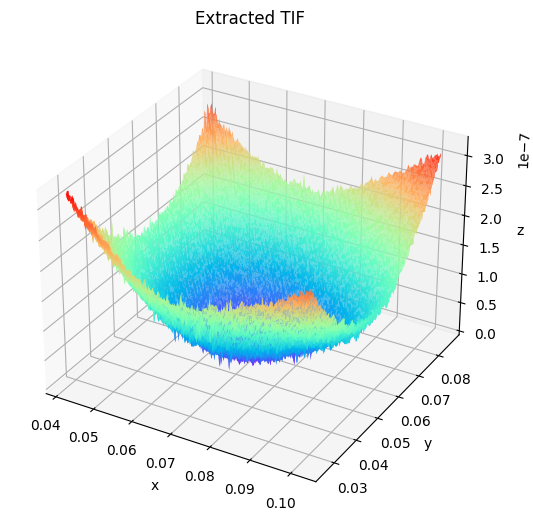

In [63]:
fig=plt.figure()
ax = Axes3D(fig)
ax.plot_surface(X, Y, E, cmap='rainbow', rstride=1, cstride=1)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
plt.title('Extracted TIF')

